# Design Patterns for Data & AI Code

A **design pattern** is a proven solution to a design problem that appears again and again. This lesson covers the patterns that appear most often in data, ML and LLM code, with Python-specific implementations (functions, decorators and protocols instead of large class hierarchies).

**After this lesson you can:**

1. Use the **Strategy**, **Registry/Factory**, **Adapter**, **Pipeline**, **Repository** and **Retry/Circuit Breaker** patterns.
2. Recognise them in libraries that you use (scikit-learn, Hugging Face, LangChain).
3. Select a pattern for a problem.

## 1. Strategy: Interchangeable Algorithms

**Problem:** the same task has several algorithms (several ways to score, to rank, to split data).
**Solution:** pass the algorithm as an object or a function. In Python, a function is often enough.

In [1]:
from collections.abc import Callable

import numpy as np

Scorer = Callable[[np.ndarray, np.ndarray], float]

def accuracy(y_true, y_pred):
    return float((y_true == y_pred).mean())

def recall(y_true, y_pred):
    positives = y_true == 1
    return float((y_pred[positives] == 1).mean())

def evaluate(y_true, y_pred, scorers: dict[str, Scorer]) -> dict[str, float]:
    return {name: round(fn(y_true, y_pred), 3) for name, fn in scorers.items()}

y_true = np.array([1, 0, 1, 1, 0, 0, 1, 0])
y_pred = np.array([1, 0, 0, 1, 0, 1, 1, 0])
print(evaluate(y_true, y_pred, {"accuracy": accuracy, "recall": recall}))

{'accuracy': 0.75, 'recall': 0.75}


## 2. Registry and Factory: Create Objects by Name

**Problem:** a configuration file says `model: "mean"` or `model: "linear"`, and the code must create the matching object.
**Solution:** a registry maps names to classes; a decorator registers each class; a factory function creates objects by name. Hugging Face `AutoModel.from_pretrained(name)` and scikit-learn's `get_scorer(name)` work this way.

In [2]:
MODELS: dict[str, type] = {}

def register(name: str):
    def decorator(cls):
        MODELS[name] = cls
        return cls
    return decorator

@register("mean")
class MeanModel:
    def fit(self, x, y):
        self.value = y.mean(); return self
    def predict(self, x):
        return np.full(len(x), self.value)

@register("linear")
class LinearModel:
    def fit(self, x, y):
        self.coef = np.polyfit(x, y, 1); return self
    def predict(self, x):
        return np.polyval(self.coef, x)

def create_model(config: dict):
    try:
        return MODELS[config["model"]]()
    except KeyError:
        raise ValueError(f"unknown model {config['model']!r}; choose from {sorted(MODELS)}") from None

rng = np.random.default_rng(1)
x = rng.uniform(0, 10, 50); y = 2 * x + 1 + rng.normal(0, 1, 50)
for cfg in [{"model": "mean"}, {"model": "linear"}]:
    m = create_model(cfg).fit(x, y)
    print(cfg, "-> prediction at x=5:", round(float(m.predict(np.array([5.0]))[0]), 2))

{'model': 'mean'} -> prediction at x=5: 11.29
{'model': 'linear'} -> prediction at x=5: 10.9


## 3. Adapter: One Interface for Different Providers

**Problem:** different libraries or APIs do the same job with different method names and formats (for example LLM providers).
**Solution:** an adapter class wraps each provider behind one common interface. Your code depends only on the interface, so you can switch providers with one line. The two "providers" below are local stand-ins that mimic the response shapes of real SDKs.

In [3]:
from typing import Protocol

class ChatModel(Protocol):
    def complete(self, prompt: str) -> str: ...

class VendorAClient:                       # stand-in for an SDK with a "messages" API
    def create(self, messages: list[dict]) -> dict:
        return {"choices": [{"message": {"content": f"A says: {messages[-1]['content'][::-1]}"}}]}

class VendorBClient:                       # stand-in for an SDK with a "generate" API
    def generate(self, text: str, max_tokens: int = 50) -> list[str]:
        return [f"B says: {text.upper()}"]

class VendorAAdapter:
    def __init__(self, client: VendorAClient):
        self.client = client
    def complete(self, prompt: str) -> str:
        return self.client.create([{"role": "user", "content": prompt}])["choices"][0]["message"]["content"]

class VendorBAdapter:
    def __init__(self, client: VendorBClient):
        self.client = client
    def complete(self, prompt: str) -> str:
        return self.client.generate(prompt)[0]

def summarise(model: ChatModel, text: str) -> str:   # business code: knows only the interface
    return model.complete(f"summarise: {text}")

for model in (VendorAAdapter(VendorAClient()), VendorBAdapter(VendorBClient())):
    print(summarise(model, "hello"))

A says: olleh :esirammus
B says: SUMMARISE: HELLO


## 4. Pipeline: Steps That Feed Each Other

**Problem:** data passes through several steps (clean → transform → model), and you want to add, remove or reorder steps.
**Solution:** each step has the same interface; a pipeline object runs them in order. scikit-learn `Pipeline`, LangChain's `|` operator and Unix pipes all follow this pattern.

In [4]:
from dataclasses import dataclass, field

@dataclass
class Pipeline:
    steps: list[tuple[str, Callable]] = field(default_factory=list)

    def add(self, name: str, fn: Callable) -> "Pipeline":
        self.steps.append((name, fn)); return self

    def __or__(self, step: tuple[str, Callable]) -> "Pipeline":    # allow `pipeline | ("name", fn)`
        return Pipeline(self.steps + [step])

    def run(self, data, trace: bool = False):
        for name, fn in self.steps:
            data = fn(data)
            if trace:
                print(f"after {name:<12}: {data}")
        return data

text_pipeline = (Pipeline()
                 | ("strip", str.strip)
                 | ("lower", str.lower)
                 | ("tokenise", str.split)
                 | ("no_stop", lambda toks: [t for t in toks if t not in {"the", "a", "is"}]))
text_pipeline.run("  The Model is a Transformer  ", trace=True)

after strip       : The Model is a Transformer
after lower       : the model is a transformer
after tokenise    : ['the', 'model', 'is', 'a', 'transformer']
after no_stop     : ['model', 'transformer']


['model', 'transformer']

## 5. Repository and Circuit Breaker

**Repository** — *problem:* business code is full of SQL or file paths. *Solution:* a class with methods such as `get()` and `add()` hides the storage. Tests use an in-memory repository; production uses a database (M07).

**Circuit breaker** — *problem:* a failing service gets flooded with retries. *Solution:* after *k* failures, the breaker **opens** and rejects calls immediately for a cool-down period; then it lets one trial call through (**half-open**). The simulation shows the effect on a service that is down between calls 30 and 70 (synthetic).

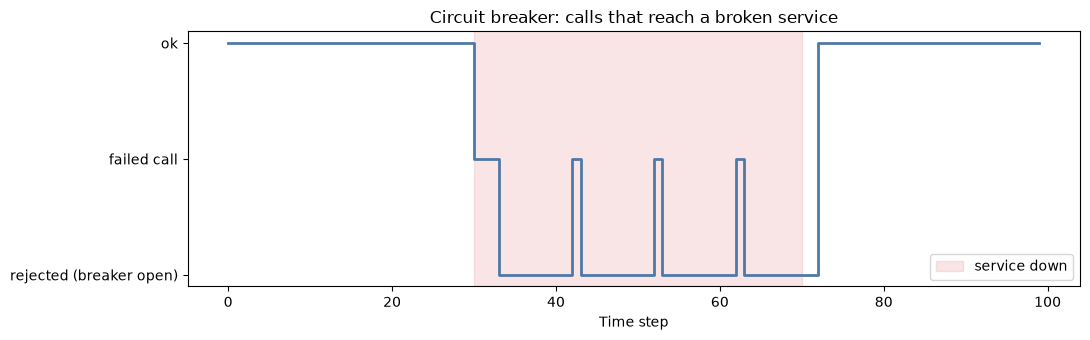

calls that hit the broken service: without breaker 40, with breaker 6 (the rest were rejected immediately)


In [5]:
import random

import matplotlib.pyplot as plt

class CircuitBreaker:
    def __init__(self, threshold: int = 3, cooldown: int = 10):
        self.threshold, self.cooldown = threshold, cooldown
        self.failures, self.open_until, self.state = 0, -1, "closed"

    def call(self, fn, now: int):
        if now < self.open_until:
            self.state = "open"
            return "rejected"                           # fail fast: do not touch the service
        self.state = "half-open" if self.failures >= self.threshold else "closed"
        try:
            result = fn(now)
            self.failures = 0
            self.state = "closed"
            return result
        except ConnectionError:
            self.failures += 1
            if self.failures >= self.threshold:
                self.open_until = now + self.cooldown
                self.state = "open"
            return "failed"

def service(now: int) -> str:
    if 30 <= now < 70:
        raise ConnectionError("down")
    return "ok"

cb = CircuitBreaker()
calls_without = [("failed" if 30 <= t < 70 else "ok") for t in range(100)]
calls_with = [cb.call(service, t) for t in range(100)]

fig, ax = plt.subplots(figsize=(11, 3.5))
codes = {"ok": 2, "failed": 1, "rejected": 0}
ax.step(range(100), [codes[c] for c in calls_with], where="post", color="#4E79A7", lw=2)
ax.set_yticks([0, 1, 2], ["rejected (breaker open)", "failed call", "ok"])
ax.axvspan(30, 70, color="#E15759", alpha=0.15, label="service down")
ax.set(title="Circuit breaker: calls that reach a broken service", xlabel="Time step")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
print(f"calls that hit the broken service: without breaker {calls_without.count('failed')}, "
      f"with breaker {calls_with.count('failed')} (the rest were rejected immediately)")

## Choosing a Pattern

| Problem | Pattern |
| :--- | :--- |
| several algorithms for one task | Strategy |
| create objects from a name in a configuration | Registry + Factory |
| different APIs for the same job | Adapter |
| a sequence of transformations | Pipeline |
| business code mixed with storage code | Repository |
| a dependency that can fail or be slow | Retry + Circuit Breaker |

*Insight: Most Python patterns need only functions, decorators and small protocols, not deep class hierarchies. Use a pattern when it removes a real problem (duplicated `if/elif` blocks, code you cannot test, a provider you cannot replace), not to make code look sophisticated.*

## Real-World Use Case or Analogy

Design patterns are like **standard building elements in architecture**: doors, stairs, windows. An architect does not invent a new kind of door for each house; they select a proven design and adapt its size. Everybody who sees "a staircase" in the plan knows what it does.

You meet these patterns in every library of this course: scikit-learn pipelines and scorers (M10, M16), Hugging Face `Auto*` registries (M26), LangChain chat-model adapters and runnable pipelines (M29), and circuit breakers in API gateways (M30).